# Evaluation Code

---

## Quadratic Weighted Kappa (QWK)

Let's begin with our primary metric: quadratic weighted kappa (QWK). 

In [4]:
import numpy as np
from sklearn.metrics import cohen_kappa_score

# --- Dummy Data ---
y_true = np.array([0, 1, 2, 3, 4, 3, 2, 1, 0, 3])
y_pred_1 = np.array([0, 2, 2, 3, 4, 3, 1, 1, 0, 2])
y_pred_2 = np.array([0, 3, 2, 3, 4, 3, 4, 1, 0, 1])
y_pred_3 = np.array([0, 1, 2, 3, 4, 3, 0, 1, 0, 4])

qwk_1 = cohen_kappa_score(y_true, y_pred_1, weights='quadratic')
qwk_2 = cohen_kappa_score(y_true, y_pred_2, weights='quadratic')
qwk_3 = cohen_kappa_score(y_true, y_pred_3, weights='quadratic')

print(f"Quadratic Weighted Kappa (First Predictions): {qwk_1:.4f}")
print(f"Quadratic Weighted Kappa (Second Predictions): {qwk_2:.4f}")
print(f"Quadratic Weighted Kappa (Second Predictions): {qwk_3:.4f}")

Quadratic Weighted Kappa (First Predictions): 0.9080
Quadratic Weighted Kappa (Second Predictions): 0.6859
Quadratic Weighted Kappa (Second Predictions): 0.8768


The examples above emphasize the **disagreement penalty** of QWK. The first set of predictions misclassifies 3/10 examples with a QWK of 0.9080. The second set misclassifies the same number, except the distance of these misclassifications is 2 instead of 1, dropping the QWK to 0.8768. The third set only misclassifies 2 examples by distances 1 and 2. Despite fewer misclassifications, the QWK is still lower than the first set. In this case, it's preferable to mislcassify 2 images by 1 level than to misclassify 1 image by 2 levels.

## Comparison With Other Metrics

Let's compare QWK with our other metrics - precision, recall, F1-score, and plot the ROC and PRC:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    cohen_kappa_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    precision_recall_curve
)

# --- Dummy Data ---
y_true = np.array([0, 1, 2, 3, 4, 3, 2, 1, 0, 3])
y_pred_1 = np.array([0, 2, 2, 3, 4, 3, 1, 1, 0, 2])
y_pred_2 = np.array([0, 3, 2, 3, 4, 3, 4, 1, 0, 1])
y_pred_3 = np.array([0, 1, 2, 3, 4, 3, 0, 1, 0, 1])

predictions = [y_pred_1, y_pred_2, y_pred_3]
names = ["First Predictions", "Second Predictions", "Third Predictions"]

for name, y_pred in zip(names, predictions):
    qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    print(f"\n{name}:")
    print(f"  Quadratic Weighted Kappa: {qwk:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall: {recall:.4f}")
    print(f"  F1-score: {f1:.4f}")


First Predictions:
  Quadratic Weighted Kappa: 0.9080
  Precision: 0.7667
  Recall: 0.7000
  F1-score: 0.7200

Second Predictions:
  Quadratic Weighted Kappa: 0.6859
  Precision: 0.7500
  Recall: 0.7000
  F1-score: 0.7000

Third Predictions:
  Quadratic Weighted Kappa: 0.7838
  Precision: 0.8667
  Recall: 0.8000
  F1-score: 0.7933


These metrics are generally correlated. Again, the main difference comes from large disagreements, or very inaccurate predictions. This is exemplified between the first and third sets of predictions, where QWK decreases and F1-score increases due to fewer but larger misclassifications.

## ROC and PRC

Let's plot the ROC curve and PRC to visualize the accuracy of some dummy predictions:

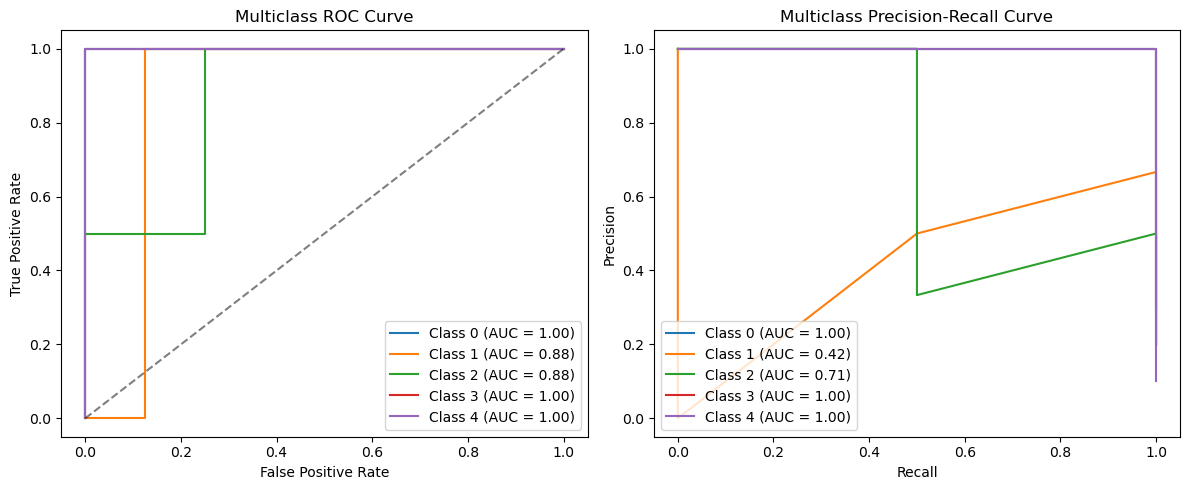

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# === Dummy true labels (multiclass) ===
y_true = np.array([0, 1, 2, 3, 4, 3, 2, 1, 0, 3])

# === Dummy softmax-like prediction scores (one row per sample, one column per class) ===
y_scores = np.array([
    [0.9, 0.05, 0.02, 0.02, 0.01],
    [0.1, 0.2, 0.6, 0.05, 0.05],
    [0.05, 0.05, 0.8, 0.05, 0.05],
    [0.05, 0.1, 0.05, 0.75, 0.05],
    [0.05, 0.05, 0.05, 0.05, 0.8],
    [0.05, 0.05, 0.1, 0.75, 0.05],
    [0.1, 0.7, 0.15, 0.025, 0.025],
    [0.15, 0.6, 0.1, 0.1, 0.05],
    [0.85, 0.1, 0.02, 0.02, 0.01],
    [0.05, 0.1, 0.5, 0.3, 0.05],
])

# === Binarize the true labels for multiclass ROC/PR computation ===
classes = [0, 1, 2, 3, 4]
y_true_bin = label_binarize(y_true, classes=classes)
n_classes = len(classes)

# === Compute ROC and PRC metrics ===
fpr = dict()
tpr = dict()
roc_auc = dict()
precision = dict()
recall = dict()
prc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_scores[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], y_scores[:, i])
    prc_auc[i] = auc(recall[i], precision[i])

# === Plot ROC and PRC curves ===
plt.figure(figsize=(12, 5))

# ROC Curve
plt.subplot(1, 2, 1)
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f"Class {i} (AUC = {roc_auc[i]:.2f})")
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.title("Multiclass ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc='lower right')

# PRC Curve
plt.subplot(1, 2, 2)
for i in range(n_classes):
    plt.plot(recall[i], precision[i], label=f"Class {i} (AUC = {prc_auc[i]:.2f})")
plt.title("Multiclass Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc='lower left')

plt.tight_layout()
plt.show()


Since ROC and PRC are designed to evaluate the model at various thresholds, we needed to replace our dummy predictions with probabilities, representing the predicted likelihood of the example belonging to each class. Since we have only 10 data points, the curves representing each class do not look very smooth, but they demonstrate how ideal predictions behave. For ROC, the curve aligns with the left and top borders and for PR, the top and right borders.